In [56]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.base.model import GenericLikelihoodModel
import seaborn as sns
from sklearn.model_selection import train_test_split
import statsmodels.api as sm
import statsmodels.formula.api as smf
from scipy.stats import norm


# Survival Lab

We've looked at normal-linear regression and probit regression from a likelihood perspective, which yields two log-likelihoods:
$$
LL(\beta,\sigma) = - n \log( \sqrt{2\pi} ) - n \log(\sigma) - \frac{1}{2\sigma^2} \sum_{i=1}^n (y_i - x_i \beta)^2
$$
and
$$
LL(\beta) = \sum_{i=1}^N y_i \log(\Phi(x_i \cdot \beta/\sigma)) + (1-y_i) \log(1-\Phi(x_i \cdot \beta/\sigma)).
$$
This lab combines them by looking at **right-censored** survival data.

We are going to use the Metabric breast cancer dataset to predict how long someone survives after being treated for breast cancer. For the regressions that follow, include the following as numeric variables:

- 'Age at Diagnosis'
- 'Lymph nodes examined positive'
- 'Mutation Count'
- 'Tumor Size'

and the following as categorical variables (one-hot encode them):

- 'Chemotherapy'
- 'Hormone Therapy'
- 'Radio Therapy'
- 'Tumor Stage'

The outcome variable of interest is the log of `Overall Survival (Months)`, which we'll refer to as log-months.

1. Load the `./data/metabric.csv` data. Tabulate `Overall Survival Status` to see who is alive or dead at the time the study ends. Make a kernel density plot of `Overall Survival (Months)`, hued by `Overall Survival Status`, to see the difference between survival duration for those alive and those dead at the time the study ended. **Drop the observations for which `Tumor Stage` is zero.**
2. Use Scikit's `train_test_split` with a `test_size` of .2. There are two tempting -- but ultimately incorrect -- ways to handle the Survival Status issue:
    - Use the reported `Overall Survival (Months)` as the target variable
    - Drop everyone who is alive at the time the study ends
Run these flawed regressions and save the coefficients and test-set predictions. Explain clearly how the first option is an example of imputation and the second treats survival as missing data.
3. Derive the log-likelihood for a model where the normal density is used for log-months when the subject died during the study (and log-months is observed, as in linear-normal regression), and the survival probability based on the Normal distribution is used when the patient is alive when the study ends (and log-months is a latent variable, as in a binary probit).
4. We want to estimate the model in part 3. You can do this with the `lifelines` package's `LogNormalAFTFitter`, or use the code chunk below to extend StatsModels to estimate this kind of model.
5. Compare the coefficients and test-set predictions (be careful to keep an eye on the censoring) for the censored MLE and the two linear models. Can you identify any groups who receive systematically biased predictions from the imputation and missing data approaches? 

In [48]:


class CensoredNormalMLE(GenericLikelihoodModel):
    def __init__(self, endog, exog, event):
        super().__init__(endog, exog, extra_params_names=["log_sigma"])
        self.event = np.asarray(event)

    def nloglikeobs(self, params):
        beta, log_sigma = params[:-1], params[-1]
        sigma = np.exp(log_sigma)
        z = (self.endog - self.exog @ beta) / sigma
        ll_dead = norm.logpdf(z) - log_sigma
        ll_alive = norm.logsf(z)
        return -np.where(self.event == 1, ll_dead, ll_alive)

# Load and prepare the Metabric data
df = pd.read_csv("./data/metabric.csv")
df = df[df["Tumor Stage"] != 0].copy()

df.head()

,Age at Diagnosis,Type of Breast Surgery,Cancer Type,Chemotherapy,Hormone Therapy,Lymph nodes examined positive,Mutation Count,Nottingham prognostic index,Overall Survival (Months),Overall Survival Status,Radio Therapy,TMB (nonsynonymous),Tumor Size,Tumor Stage
0,43.19,BREAST CONSERVING,Breast Cancer,NO,YES,0.0,2.0,4.020,84.633333,0:LIVING,YES,2.615035,10.0,1.0
1,48.87,MASTECTOMY,Breast Cancer,YES,YES,1.0,2.0,4.030,163.700000,1:DECEASED,NO,2.615035,15.0,2.0
2,47.68,MASTECTOMY,Breast Cancer,YES,YES,3.0,1.0,4.050,164.933333,0:LIVING,YES,1.307518,25.0,2.0
3,76.97,MASTECTOMY,Breast Cancer,YES,YES,8.0,2.0,6.080,41.366667,1:DECEASED,YES,2.615035,40.0,2.0
4,78.77,MASTECTOMY,Breast Cancer,NO,YES,0.0,4.0,4.062,7.800000,1:DECEASED,YES,5.230071,31.0,4.0



1. Load the `./data/metabric.csv` data. Tabulate `Overall Survival Status` to see who is alive or dead at the time the study ends. Make a kernel density plot of `Overall Survival (Months)`, hued by `Overall Survival Status`, to see the difference between survival duration for those alive and those dead at the time the study ended. **Drop the observations for which `Tumor Stage` is zero.**

Overall Survival Status
1:DECEASED    768
0:LIVING      573
Name: count, dtype: int64
Overall Survival Status
1:DECEASED    0.572707
0:LIVING      0.427293
Name: proportion, dtype: float64


Text(0.5, 1.0, 'KDE of Overall Survival by Survival Status')

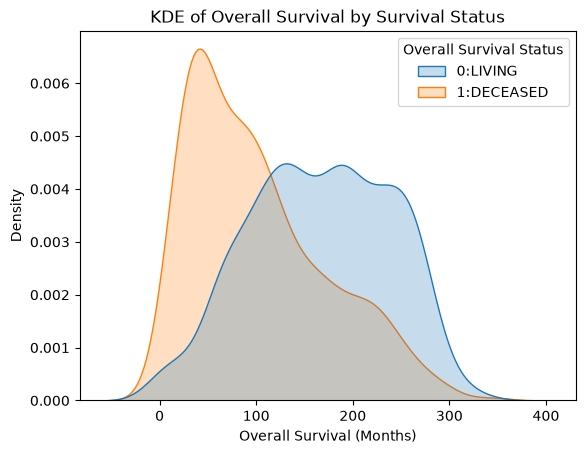

In [53]:

print(df["Overall Survival Status"].value_counts())
print(df["Overall Survival Status"].value_counts(normalize=True))

sns.kdeplot(
    data=df,
    x="Overall Survival (Months)",
    hue="Overall Survival Status",
    common_norm=False,
    fill=True
)
plt.title('KDE of Overall Survival by Survival Status')

- This graph shows the overall patient survival status. 
    - `LIVING`: patient was still alive when the study ended
    -  `DECEASED`: patient's death was observed during the study. 

2. Use Scikit's `train_test_split` with a `test_size` of .2. There are two tempting -- but ultimately incorrect -- ways to handle the Survival Status issue:
    - Use the reported `Overall Survival (Months)` as the target variable
    - Drop everyone who is alive at the time the study ends
Run these flawed regressions and save the coefficients and test-set predictions. Explain clearly how the first option is an example of imputation and the second treats survival as missing data.

In [75]:
df = df[df["Tumor Stage"] != 0].copy()

numeric_cols = [
    "Age at Diagnosis",
    "Lymph nodes examined positive",
    "Mutation Count",
    "Tumor Size",
]
categorical_cols = [
    "Chemotherapy",
    "Hormone Therapy",
    "Radio Therapy",
    "Tumor Stage",
]

X = pd.get_dummies(
    df[numeric_cols + categorical_cols],
    columns=categorical_cols,
    drop_first=True,
    dtype=float,
)
X = pd.concat([pd.Series(1.0, index=X.index, name="const"), X], axis=1)

y = np.log(df["Overall Survival (Months)"]).astype(float)

status = df["Overall Survival Status"].astype(str).str.strip().str.upper()
event = status.str.contains("DECEASE|DEAD|DIED", regex=True).astype(int)

# Remove rows containing missing model variables
valid = X.notna().all(axis=1) & y.notna() & event.notna()
X = X.loc[valid]
y = y.loc[valid]
event = event.loc[valid]



In [73]:
finite = np.isfinite(y)
X, y, event = X.loc[finite], y.loc[finite], event.loc[finite]

X_train, X_test, y_train, y_test, train_event, test_event = train_test_split(
    X, y, event, test_size=0.2, random_state=42
)

#dropping patients that are alive
train_dead = train_event == 1
ols_dead = sm.OLS(y_train[train_dead], X_train[train_dead]).fit()
coef_dead = ols_dead.params
pred_dead = pd.Series(ols_dead.predict(X_test), index=X_test.index, name="pred_dead_only")

coefs = pd.DataFrame({"naive_all": coef_all, "dead_only": coef_dead})
coefs.to_csv("flawed_coefficients.csv")

preds = pd.concat([y_test.rename("actual_log_months"),
                   test_event.rename("event"),
                   pred_all, pred_dead], axis=1)
preds.to_csv("flawed_test_predictions.csv")

rmse = lambda a, b: np.sqrt(np.mean((a - b) ** 2))
print(coefs.round(4))
print("Test RMSE, naive (all):      ", rmse(y_test, pred_all))
print("Test RMSE, dead-only model:  ", rmse(y_test, pred_dead))
print("Censored share in train:     ", 1 - train_event.mean())

                               naive_all  dead_only
const                             5.2934     4.6594
Age at Diagnosis                 -0.0086    -0.0029
Lymph nodes examined positive    -0.0384    -0.0279
Mutation Count                    0.0064     0.0096
Tumor Size                       -0.0038    -0.0018
Chemotherapy_YES                 -0.2191    -0.3931
Hormone Therapy_YES               0.0864     0.2423
Radio Therapy_YES                 0.1202     0.0392
Tumor Stage_2.0                  -0.1872    -0.2238
Tumor Stage_3.0                  -0.4052    -0.5528
Tumor Stage_4.0                  -0.7073    -1.0499
Test RMSE, naive (all):       0.7669003709495955
Test RMSE, dead-only model:   0.827944658244471
Censored share in train:      0.42630597014925375


- The intercept (5.2934 vs 4.6594):  the dead_only model's baseline survival is about 46.59%; and this could be the selection problem. Removing the 43% of training patients who were still alive leaves a sample enriched for early deaths
- Age (-0.0086 vs. -0.0029): The effect of age becomes substantially weaker among patients who died. This suggests that restricting the sample to observed deaths can reduce the apparent strength of certain relationships.
- the gradient is steeper in the dead-only model. Stage 4 vs. stage 1 is -1.05 (about 65% shorter) against -0.71 (about 51% shorter) for the naive model. Among patients who died, a late stage is strongly linked to dying quickly. Early-stage patients who lived long are mostly the censored ones, so they were dropped
- Chemo (-0.2191 vs  -0.3931): both are negative which could probably be confounding
-  Hormone and radio therapies: the effects shift in different directions when restricting the sample to patients who died.

- The dead-only model performs worse (0.83 vs. 0.77), as expected, because it is trained exclusively on patients who died during the study and therefore tends to underestimate survival times.


3. Derive the log-likelihood for a model where the normal density is used for log-months when the subject died during the study (and log-months is observed, as in linear-normal regression), and the survival probability based on the Normal distribution is used when the patient is alive when the study ends (and log-months is a latent variable, as in a binary probit).

- let Ti be the true survival: Y= log Ti
$$
Y_i = x_i^\top \beta + \varepsilon_i,
\qquad
\varepsilon_i \sim N(0, \sigma^2)
$$

- Contribution of a patient who died: 
$$
f(y_i \mid x_i)
=
\frac{1}{\sigma}\,
\phi\left(
\frac{y_i - x_i^\top\beta}{\sigma}
\right)
=
\frac{1}{\sigma\sqrt{2\pi}}
\exp\left\{
-\frac{(y_i - x_i^\top\beta)^2}{2\sigma^2}
\right\}
$$


- contribution of a patient alive at the end:
$$
P(Y_i > y_i \mid x_i)
=
1 - \Phi\left(
\frac{y_i - x_i^\top\beta}{\sigma}
\right)
=
\Phi\left(
\frac{x_i^\top\beta - y_i}{\sigma}
\right)
$$


- the log-likelihood: 
$$
\ell(\beta,\sigma)
=
\sum_{i:\,d_i=1}
\left[
-\log\sigma
-\frac{1}{2}\log(2\pi)
-\frac{(y_i-x_i^\top\beta)^2}{2\sigma^2}
\right]
+
\sum_{i:\,d_i=0}
\log\Phi\left(
\frac{x_i^\top\beta-y_i}{\sigma}
\right)
$$

4. We want to estimate the model in part 3. You can do this with the `lifelines` package's `LogNormalAFTFitter`, or use the code chunk below to extend StatsModels to estimate this kind of model.

In [86]:


class CensoredNormalMLE(GenericLikelihoodModel):
    def __init__(self, endog, exog, event, **kwds):
        super().__init__(endog, exog, extra_params_names=["log_sigma"], **kwds)
        self.event = np.asarray(event)

    def loglikeobs(self, params):
        beta = params[:-1]
        sigma = np.exp(params[-1])
        z = (np.asarray(self.endog) - np.asarray(self.exog) @ beta) / sigma
        return np.where(self.event == 1,
                        norm.logpdf(z) - np.log(sigma),   
                        norm.logsf(z))                    
params = mle.params
beta_mle = params.iloc[:-1] if hasattr(params, "iloc") else pd.Series(params[:-1], index=X_train.columns)
sigma_mle = np.exp(np.asarray(params)[-1])
print("sigma:", sigma_mle)

pred_mle = pd.Series(np.asarray(X_test) @ np.asarray(beta_mle), index=X_test.index, name="pred_mle")

sigma: 1.0868905769008192


signma (the standard deviation) of the error on log-month scale. survival times are very spread out. 

In [87]:
comparison = pd.DataFrame({
    "naive_all": coef_all,
    "dead_only": coef_dead,
    "censored_mle": beta_mle,
})
print(comparison.round(4))
comparison.to_csv("coefficient_comparison.csv")

                               naive_all  dead_only  censored_mle
const                             5.2934     4.6594        6.7612
Age at Diagnosis                 -0.0086    -0.0029       -0.0218
Lymph nodes examined positive    -0.0384    -0.0279       -0.0567
Mutation Count                    0.0064     0.0096       -0.0168
Tumor Size                       -0.0038    -0.0018       -0.0087
Chemotherapy_YES                 -0.2191    -0.3931       -0.2726
Hormone Therapy_YES               0.0864     0.2423        0.2613
Radio Therapy_YES                 0.1202     0.0392        0.2135
Tumor Stage_2.0                  -0.1872    -0.2238       -0.3224
Tumor Stage_3.0                  -0.4052    -0.5528       -0.5532
Tumor Stage_4.0                  -0.7073    -1.0499       -0.8468


In [88]:
mle.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                              CensoredNormalMLE Results                              
=====================================================================================
Dep. Variable:     Overall Survival (Months)   Log-Likelihood:                -1201.4
Model:                     CensoredNormalMLE   AIC:                             2427.
Method:                   Maximum Likelihood   BIC:                             2487.
Date:                       Tue, 24 Nov 2026                                         
Time:                               17:43:45                                         
No. Observations:                       1072                                         
Df Residuals:                           1060                                         
Df Model:                                 10                                         
=================================================================================================
                                    coef    std err          z      P>|z|      [0.025      0.975]
-------------------------------------------------------------------------------------------------
const                             6.7612      0.232     29.142      0.000       6.307       7.216
Age at Diagnosis                 -0.0218      0.003     -6.513      0.000      -0.028      -0.015
Lymph nodes examined positive    -0.0567      0.011     -5.363      0.000      -0.077      -0.036
Mutation Count                   -0.0168      0.009     -1.826      0.068      -0.035       0.001
Tumor Size                       -0.0087      0.003     -2.807      0.005      -0.015      -0.003
Chemotherapy_YES                 -0.2726      0.117     -2.337      0.019      -0.501      -0.044
Hormone Therapy_YES               0.2613      0.084      3.093      0.002       0.096       0.427
Radio Therapy_YES                 0.2135      0.081      2.632      0.008       0.055       0.373
Tumor Stage_2.0                  -0.3224      0.096     -3.371      0.001      -0.510      -0.135
Tumor Stage_3.0                  -0.5532      0.178     -3.106      0.002      -0.902      -0.204
Tumor Stage_4.0                  -0.8468      0.510     -1.662      0.097      -1.846       0.152
log_sigma                         0.0833      0.030      2.775      0.006       0.024       0.142
=================================================================================================
"""

Because 43% of the patients are cencored, the test-set outcomes for those patients are only lower bounds, so plain prediction error (and overall RMSE) isn't a valid way to compare the three model. Based on the coefficients, I expect both the naive (imputation) and dead-only (missing data) models to underpredict survival most for young, low-stage, low-node, small-tumor patients, who are also the most likely to be censored. in addition, similar pattern may occur among patients receiving chemo therapy and hormone therapy. The dead-only model may exhibit more substantial selection bias because it excludes all patients who survived until the end of the study. the maginitude and direction of this differences must be confirmed empirically. 